# Rain Tomorrow: Classification Pipeline

End-to-end walkthrough of the project: data overview, model training, evaluation and batch inference.
The reusable logic lives in the `rain_tomorrow` package (`src/rain_tomorrow/`); this notebook only orchestrates it.

> Run it from the `notebooks/` directory after installing the project with `pip install -e ".[dev]"`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

from rain_tomorrow.evaluate import CLASS_NAMES
from rain_tomorrow.inference import run_inference
from rain_tomorrow.preprocessing import preprocess
from rain_tomorrow.train import build_model

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = ROOT / "data" / "splits" / "train.csv"
TEST_PATH = ROOT / "data" / "splits" / "test.csv"
MODEL_PATH = ROOT / "models" / "model.pkl"


## 1. Data overview

In [2]:
train_raw = pd.read_csv(TRAIN_PATH)
print(f"Train: {train_raw.shape[0]:,} rows x {train_raw.shape[1]} columns")
train_raw["RainTomorrow"].value_counts(dropna=False, normalize=True).rename("share").to_frame()

Train: 20,169 rows x 23 columns


,share
RainTomorrow,
No,0.814022
Yes,0.171848
NaN,0.014131


In [3]:
missing = train_raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].to_frame("missing_share").style.format("{:.1%}")

,missing_share
Sunshine,56.0%
Evaporation,44.0%
Cloud9am,35.4%
Cloud3pm,34.9%
WindDir9am,7.5%
Pressure9am,4.2%
Pressure3pm,4.2%
WindGustDir,1.5%
WindGustSpeed,1.5%
RainToday,1.4%


## 2. Preprocessing and training

`Evaporation` and `Sunshine` are dropped because of their share of missing values. The remaining missing values are
imputed per month, wind directions are collapsed to four compass points, and numeric features are scaled with
`RobustScaler`. The model is a class-balanced logistic regression.

The model below is trained in memory only; the committed artifact `models/model.pkl` is left untouched.
Use `python -m rain_tomorrow.train` to regenerate it.

In [4]:
X_train, y_train = preprocess(train_raw)
print("Feature matrix:", X_train.shape)

fresh_model = build_model().fit(X_train, y_train)
print("Converged in", fresh_model.n_iter_[0], "iterations")

Feature matrix: (19884, 27)


Converged in 312 iterations


## 3. Evaluation on the test set

Evaluates the committed model (`models/model.pkl`).

In [5]:
model = joblib.load(MODEL_PATH)
X_test, y_test = preprocess(pd.read_csv(TEST_PATH))

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

     No rain     0.9508    0.8111    0.8754      3552
        Rain     0.4558    0.7904    0.5782       711

    accuracy                         0.8076      4263
   macro avg     0.7033    0.8008    0.7268      4263
weighted avg     0.8683    0.8076    0.8258      4263



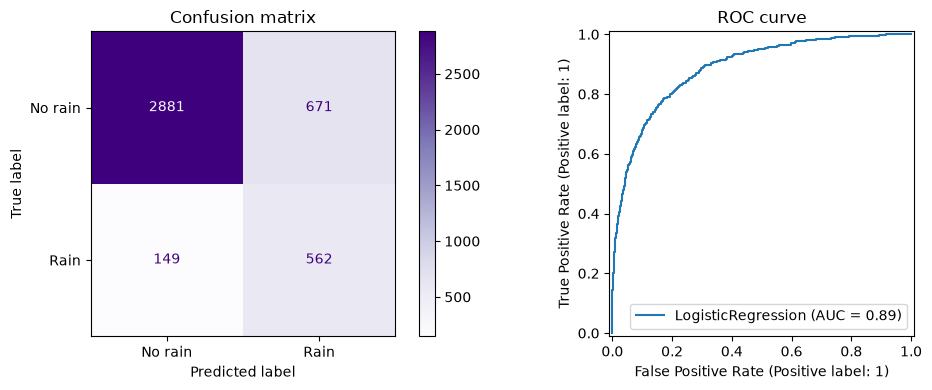

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Purples", ax=axes[0])
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1])
axes[1].set_title("ROC curve")
plt.tight_layout()
plt.show()

## 4. Batch inference

Same code path used by the Docker image: read raw observations, preprocess, predict, write a CSV.
Predictions are written to a temporary file so the repository sample is not modified.

In [7]:
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    predictions = run_inference(ROOT / "data" / "sample" / "input.csv", Path(tmp) / "output.csv", MODEL_PATH)

predictions["RainTomorrow"].value_counts().rename(index={0: "No rain", 1: "Rain"}).to_frame("count")

,count
RainTomorrow,
No rain,713
Rain,287
